In [3]:
import pandas as pd
df = pd.read_csv("../../../data/english_transactions_5200.csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Dataset shape: (5200, 3)


,description,category,type
0,Got paid 38500 Egyptian pounds for part-time s...,Salary,Income
1,gift money brought in 5825 LE today.,Gifts,Income
2,My internship stipend of 33000 pounds arrived ...,Salary,Income
3,Income received: 10500 LE from the company.,Salary,Income
4,Received 40200 pounds for retail counter sales...,Business Income,Income



Columns: ['description', 'category', 'type']


In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nTransaction types:")
print(df["type"].value_counts())

print("\nCategories:")
print(df["category"].value_counts())

print("\nDuplicate descriptions:")
print(df["description"].duplicated().sum())

Missing values:
description    0
category       0
type           0
dtype: int64

Transaction types:
type
Income     2600
Expense    2600
Name: count, dtype: int64

Categories:
category
Salary               520
Gifts                520
Business Income      520
Freelance            520
Rental Income        520
Bills & Utilities    326
Food & Dining        325
Education            325
Transportation       325
Groceries            325
Entertainment        325
Shopping             325
Healthcare           324
Name: count, dtype: int64

Duplicate descriptions:
46


In [7]:
# Remove invalid or duplicate descriptions
df = df.dropna(
    subset=["description", "type", "category"]
).copy()

df["description"] = df["description"].astype(str).str.strip()

df = df[df["description"] != ""]
df = df.drop_duplicates(subset=["description"])

X = df["description"]

# Stratify by category to preserve category distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    df["category"],
    test_size=0.2,
    random_state=42,
    stratify=df["category"]
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4123
Testing samples: 1031


In [8]:
category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        sublinear_tf=True
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

category_model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


Test Accuracy: 1.0000

Classification Report:
                   precision    recall  f1-score   support

Bills & Utilities       1.00      1.00      1.00        65
  Business Income       1.00      1.00      1.00       103
        Education       1.00      1.00      1.00        64
    Entertainment       1.00      1.00      1.00        65
    Food & Dining       1.00      1.00      1.00        65
        Freelance       1.00      1.00      1.00       103
            Gifts       1.00      1.00      1.00       102
        Groceries       1.00      1.00      1.00        65
       Healthcare       1.00      1.00      1.00        64
    Rental Income       1.00      1.00      1.00       103
           Salary       1.00      1.00      1.00       102
         Shopping       1.00      1.00      1.00        65
   Transportation       1.00      1.00      1.00        65

         accuracy                           1.00      1031
        macro avg       1.00      1.00      1.00      1031
     wei

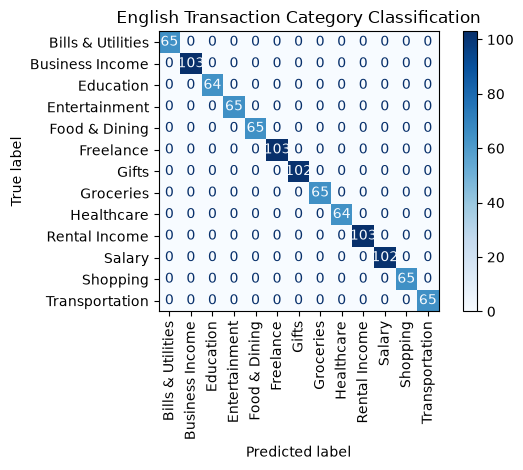

In [9]:
y_pred = category_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap="Blues"
)

plt.title("English Transaction Category Classification")
plt.tight_layout()
plt.show()

In [10]:
examples = [
    "I bought shoes from Nike for 2000 EGP",
    "I received my monthly salary of 15000 EGP",
    "I paid 250 EGP for an Uber ride",
    "I purchased groceries from Carrefour for 800 EGP",
    "I earned 3000 EGP from a freelance project"
]

predictions = category_model.predict(examples)

for text, prediction in zip(examples, predictions):
    print(f"Input: {text}")
    print(f"Predicted category: {prediction}")
    print("-" * 50)

Input: I bought shoes from Nike for 2000 EGP
Predicted category: Shopping
--------------------------------------------------
Input: I received my monthly salary of 15000 EGP
Predicted category: Salary
--------------------------------------------------
Input: I paid 250 EGP for an Uber ride
Predicted category: Transportation
--------------------------------------------------
Input: I purchased groceries from Carrefour for 800 EGP
Predicted category: Groceries
--------------------------------------------------
Input: I earned 3000 EGP from a freelance project
Predicted category: Freelance
--------------------------------------------------


In [11]:
from sklearn.metrics import f1_score

# Use the existing train/test indices
y_type_train = df.loc[X_train.index, "type"]
y_type_test = df.loc[X_test.index, "type"]

type_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

type_model.fit(X_train, y_type_train)

type_pred = type_model.predict(X_test)

print("Type Accuracy:",
      accuracy_score(y_type_test, type_pred))

print("Type Macro-F1:",
      f1_score(
          y_type_test,
          type_pred,
          average="macro"
      ))

print(classification_report(
    y_type_test,
    type_pred
))

Type Accuracy: 1.0
Type Macro-F1: 1.0
              precision    recall  f1-score   support

     Expense       1.00      1.00      1.00       518
      Income       1.00      1.00      1.00       513

    accuracy                           1.00      1031
   macro avg       1.00      1.00      1.00      1031
weighted avg       1.00      1.00      1.00      1031



In [12]:
test_sentences = [
    "My friend sent me 500 EGP for dinner",
    "I got 2000 EGP back for a returned jacket",
    "I received a refund of 350 EGP from Amazon",
    "Nike charged my card 1500 EGP",
    "My employer reimbursed me 800 EGP",
    "I made 4000 EGP selling my old laptop",
    "Paid 600 EGP to repair my phone",
    "I received 2500 EGP but I need to return it",
    "My salary arrived today",
    "I spent 150 EGP on lunch"
]

results = pd.DataFrame({
    "description": test_sentences,
    "predicted_type": type_model.predict(test_sentences),
    "predicted_category": category_model.predict(test_sentences)
})

display(results)

,description,predicted_type,predicted_category
0,My friend sent me 500 EGP for dinner,Income,Food & Dining
1,I got 2000 EGP back for a returned jacket,Expense,Shopping
2,I received a refund of 350 EGP from Amazon,Income,Salary
3,Nike charged my card 1500 EGP,Expense,Transportation
4,My employer reimbursed me 800 EGP,Income,Salary
5,I made 4000 EGP selling my old laptop,Expense,Healthcare
6,Paid 600 EGP to repair my phone,Expense,Shopping
7,I received 2500 EGP but I need to return it,Income,Salary
8,My salary arrived today,Income,Salary
9,I spent 150 EGP on lunch,Expense,Food & Dining


In [13]:
# Check how many unique sentence beginnings exist
df["first_three_words"] = (
    df["description"]
    .str.lower()
    .str.split()
    .str[:3]
    .str.join(" ")
)

print("Most common sentence beginnings:")
print(df["first_three_words"].value_counts().head(20))

print("\nUnique descriptions:")
print(df["description"].nunique())

Most common sentence beginnings:
first_three_words
today i spent              349
today i received           211
client invoice settled:     74
sales payout of             71
direct deposit of           64
rent collection from        62
grocery checkout at         49
medical payment at          47
utility bill payment        43
education expense at        42
dining receipt from         42
a tenant paid               41
wallet deduction of         37
card swipe at               37
my part-time job            34
shopping order at           34
a customer sent             33
my tenant paid              29
the company sent            20
my shop rental              19
Name: count, dtype: int64

Unique descriptions:
5154


In [14]:
new_tests = [
    "I paid 1200 EGP for a new pair of sneakers",
    "The electricity bill cost me 650 pounds",
    "I earned 4500 EGP designing a website",
    "My landlord collected 3000 EGP from me",
    "I bought fresh vegetables for 250 EGP",
    "I paid 180 EGP for lunch at a restaurant",
    "I received 12000 EGP for renting out my apartment",
    "My dental appointment cost 700 EGP",
    "The bus ticket was 35 pounds",
    "I received 2000 EGP as a birthday gift",
    "I paid 900 EGP for my online university course",
    "I made 650 EGP from my freelance photography job"
]

results = pd.DataFrame({
    "description": new_tests,
    "type": type_model.predict(new_tests),
    "category": category_model.predict(new_tests)
})

display(results)

,description,type,category
0,I paid 1200 EGP for a new pair of sneakers,Expense,Shopping
1,The electricity bill cost me 650 pounds,Expense,Bills & Utilities
2,I earned 4500 EGP designing a website,Expense,Freelance
3,My landlord collected 3000 EGP from me,Income,Salary
4,I bought fresh vegetables for 250 EGP,Expense,Groceries
5,I paid 180 EGP for lunch at a restaurant,Expense,Food & Dining
6,I received 12000 EGP for renting out my apartment,Income,Rental Income
7,My dental appointment cost 700 EGP,Expense,Healthcare
8,The bus ticket was 35 pounds,Expense,Transportation
9,I received 2000 EGP as a birthday gift,Income,Gifts


In [15]:
print("Training type distribution:")
print(df.loc[X_train.index, "type"].value_counts())

print("\nTesting type distribution:")
print(df.loc[X_test.index, "type"].value_counts())

Training type distribution:
type
Expense    2074
Income     2049
Name: count, dtype: int64

Testing type distribution:
type
Expense    518
Income     513
Name: count, dtype: int64
